# QUESTION 3: CUSTOMER SEGMENTATION USING K-MEANS CLUSTERING

### Objective

The objective of this analysis is to group mall customers based on their age, annual income and spending score using K-Means clustering. The analysis aims to identify customers with similar characteristics and spending behaviour.

In [1]:

# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load Mall Customers dataset

df = pd.read_csv("Mall_Customers.csv")

# Display first 5 rows
df.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check data types
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicates
print("\nDuplicates:", df.duplicated().sum())

# Display descriptive statistics
df.describe()


Dataset shape: (200, 5)

Data types:
CustomerID                int64
Genre                       str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Missing values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicates: 0


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


### Dataset Inspection and Descriptive Statistics

The Mall Customers dataset contains 200 customer records and five columns. The data inspection showed that there were no missing values or duplicate records, indicating that the dataset was suitable for further analysis.

The average customer age was approximately 39 years, while the average annual income was $60,560. The average spending score was 50.2 out of 100.

Customer ages ranged from 18 to 70 years, while annual incomes ranged from $15,000 to $137,000. Spending scores ranged from 1 to 99, indicating differences in customer spending behaviour.

In [4]:

# Select features for clustering

X = df[['Age', 'Annual Income (k$)',
        'Spending Score (1-100)']]

# Display first 5 rows
X.head()


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


In [5]:

# Create StandardScaler
scaler = StandardScaler()

# Scale the selected features
X_scaled = scaler.fit_transform(X)

# Display the scaled data
print(X_scaled[:5])


[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]


### Data Wrangling and Feature Scaling

Three numerical features were selected for clustering: Age, Annual Income and Spending Score. CustomerID was excluded because it is an identification variable rather than a customer characteristic.

The dataset contained no missing values or duplicate records, so no records needed to be removed.

StandardScaler was applied to standardize the selected numerical features. This ensured that the variables were measured on a comparable scale before applying K-Means clustering.

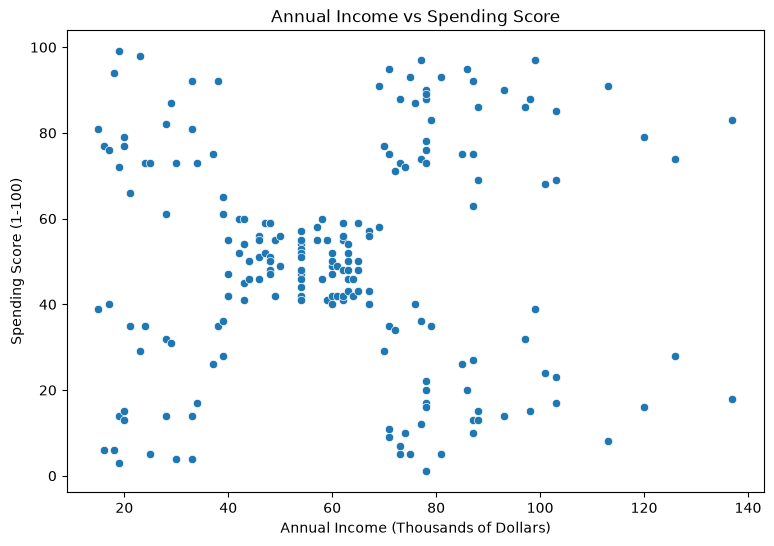

In [6]:

# Scatter plot of Income vs Spending Score

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)'
)

plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (Thousands of Dollars)')
plt.ylabel('Spending Score (1-100)')

plt.show()


### Interpretation: Annual Income vs Spending Score

The scatter plot shows the relationship between customers' annual income and spending scores.

The results indicate that customers have different spending behaviours across income levels. Some customers with low incomes have high spending scores, while others have low spending scores. Similarly, customers with higher incomes show both high and low spending patterns.

A large number of customers are concentrated around middle-income levels with moderate spending scores.

Overall, the scatter plot suggests that annual income alone does not determine customer spending behaviour. The visible patterns also suggest that customers may be divided into different groups based on their income and spending scores.

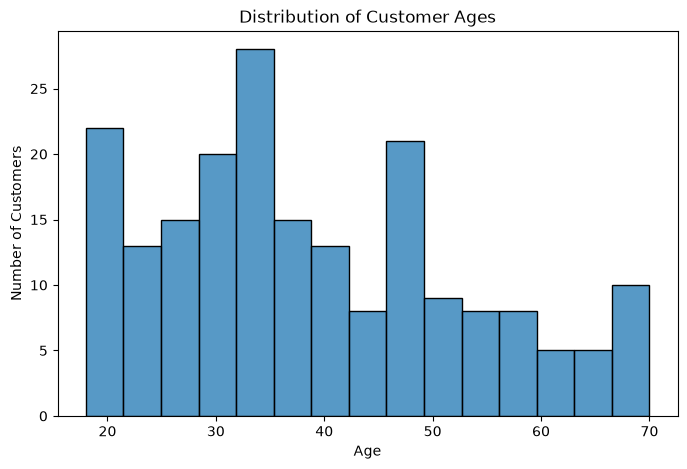

In [7]:

# Age distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Age', bins=15)

plt.title('Distribution of Customer Ages')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()


### Interpretation: Distribution of Customer Ages

The histogram shows the age distribution of 200 mall customers. Customer ages range from 18 to 70 years, with an average age of approximately 39 years.

Most customers are concentrated in the younger and middle-aged groups, particularly between 20 and 40 years. The highest concentration is observed among customers aged approximately 30 to 35 years.

The number of customers generally decreases in the older age groups. This suggests that younger and middle-aged adults make up a significant proportion of the mall's customers.

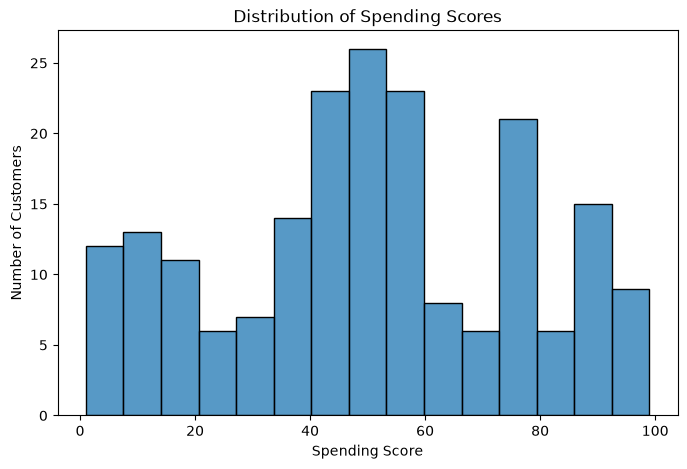

In [8]:

# Spending Score distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Spending Score (1-100)',
    bins=15
)

plt.title('Distribution of Spending Scores')
plt.xlabel('Spending Score')
plt.ylabel('Number of Customers')

plt.show()


### Interpretation: Distribution of Customer Spending Scores

The histogram shows the distribution of spending scores among 200 mall customers. Spending scores range from 1 to 99, with an average of 50.2.

Most customers have moderate spending scores, particularly between 40 and 60. However, some customers have low spending scores, while others have high spending scores.

This indicates that customers have different spending behaviours. These differences can help identify customer groups through K-Means clustering.

C:\Users\Tobias\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Tobias\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Tobias\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Tobias\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Wi

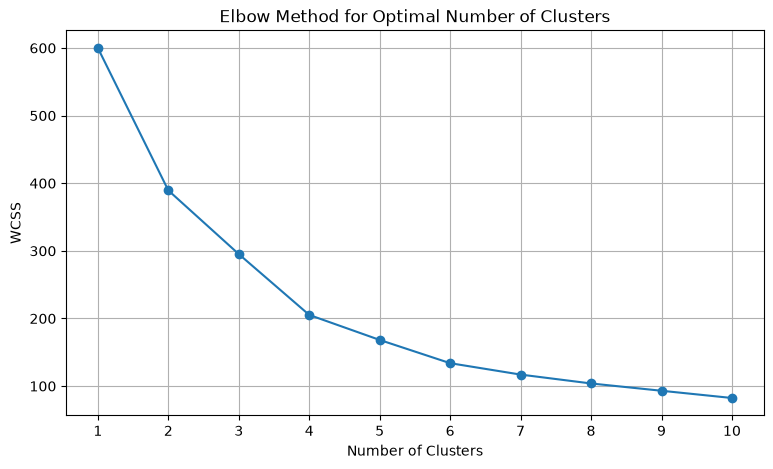

In [9]:

# Elbow Method to find the optimal number of clusters

wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method
plt.figure(figsize=(9, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()


### Interpretation: Elbow Method

The Elbow Method was used to determine a suitable number of clusters for customer segmentation.

The graph shows that WCSS decreases significantly as the number of clusters increases from 1 to 4. After 4 clusters, the reduction becomes more gradual.

Based on this observation, 4 clusters were selected for the K-Means model. This provides a reasonable balance between grouping similar customers and avoiding too many clusters.

In [10]:

# Create K-Means model with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Fit model and assign customers to clusters
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Display first 10 customers
df.head(10)


C:\Users\Tobias\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,2
3,4,Female,23,16,77,2
4,5,Female,31,17,40,2
5,6,Female,22,17,76,2
6,7,Female,35,18,6,0
7,8,Female,23,18,94,2
8,9,Male,64,19,3,0
9,10,Female,30,19,72,2


In [11]:

# Count customers in each cluster
print(df['Cluster'].value_counts().sort_index())


Cluster
0    65
1    40
2    57
3    38
Name: count, dtype: int64


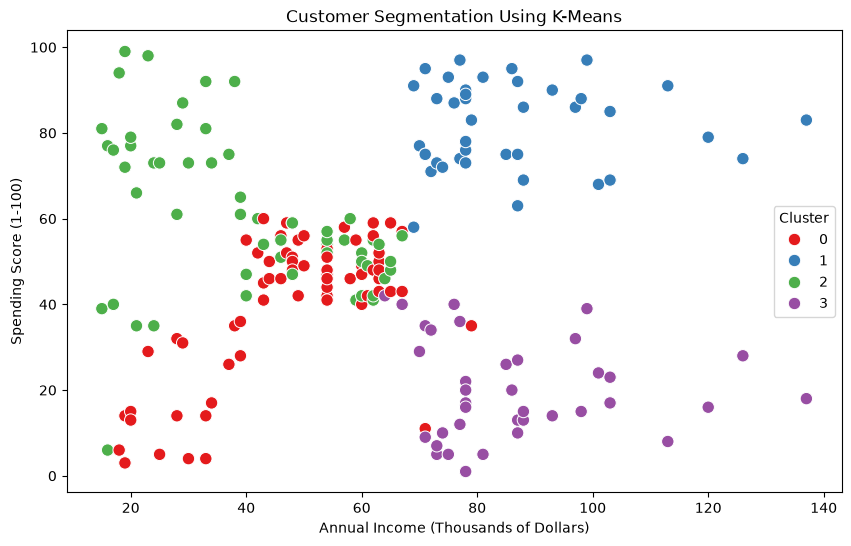

In [12]:

# Visualize customer clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set1',
    s=80
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Annual Income (Thousands of Dollars)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')

plt.show()


### Interpretation: Customer Segmentation Using K-Means

The K-Means clustering model divided the 200 mall customers into four groups based on Age, Annual Income and Spending Score.

**Cluster 0:** This group consists mainly of older customers, with an average age of approximately 54 years, an annual income of $47,710 and a spending score of 39.97. These customers generally have moderate incomes and lower spending scores.

**Cluster 1:** This group consists of relatively young, high-income customers, with an average age of 33 years, an annual income of $86,100 and a spending score of 81.53. These customers demonstrate high spending behaviour and may be suitable targets for premium products and loyalty programmes.

**Cluster 2:** This group contains younger customers, with an average age of 25 years, an annual income of $40,000 and a spending score of 60.30. Despite having lower incomes, these customers demonstrate moderate to high spending behaviour.

**Cluster 3:** This group consists of customers with an average age of 39 years, an annual income of $86,500 and a spending score of 19.58. Although these customers have relatively high incomes, their spending scores are low.

Overall, the analysis shows that customers have different spending patterns based on their age and income. The identified groups could help businesses understand customer behaviour and develop more targeted marketing strategies.

In [13]:

# Calculate average characteristics of each cluster

cluster_summary = df.groupby('Cluster')[
    ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
].mean()

# Display cluster summary
print(cluster_summary.round(2))


           Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                   
0        53.98               47.71                   39.97
1        32.88               86.10                   81.53
2        25.44               40.00                   60.30
3        39.37               86.50                   19.58


### Conclusion

The customer segmentation analysis used K-Means clustering to group 200 mall customers according to their age, annual income and spending scores.

The dataset contained no missing values or duplicate records. StandardScaler was used to standardize the numerical features before clustering.

Exploratory Data Analysis showed that customers had different spending behaviours across income levels. The Elbow Method suggested that four clusters would be a reasonable choice for customer segmentation.

The K-Means model identified four customer groups with different characteristics, including high-income high-spending customers, high-income low-spending customers, younger customers with relatively high spending scores and older customers with lower spending scores.

The findings demonstrate how clustering can help businesses understand customer differences and support more targeted marketing decisions.